1. Instalación y carga

In [ ]:
!pip install -q shap fairlearn catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.5/135.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.6 MB/s eta 0:00:00


In [ ]:
import os, json, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from google.colab import drive
from catboost import CatBoostClassifier
from fairlearn.metrics import (MetricFrame, demographic_parity_difference,
                               equalized_odds_difference, selection_rate)

SEED = 42
os.makedirs('resultados_xai', exist_ok=True)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

2. Cargar los modelos y el split de test

In [ ]:
drive.mount('/content/drive')
RUTA = '/content/drive/MyDrive/'

with open(RUTA + 'config_produccion.json', 'r', encoding='utf-8') as f:
    config = json.load(f)
cat_cols = config['cat_cols']
num_cols = config['num_cols']

df = pd.read_csv(RUTA + 'dataset_ml_entrenamiento_combinado.csv')
df[cat_cols] = df[cat_cols].astype(str)

cat_model_e1 = CatBoostClassifier(); cat_model_e1.load_model(RUTA + 'modelo_etapa1_empleo.cbm')
cat_model_e2 = CatBoostClassifier(); cat_model_e2.load_model(RUTA + 'modelo_etapa2_formalidad.cbm')

peso_formal = float(config['peso_formal_etapa2'])
clases_e2 = config['clases_etapa2']
print('Peso Formal (Etapa 2):', peso_formal)

X_test = pd.read_csv(RUTA + 'X_test_final.csv')
y_test = pd.read_csv(RUTA + 'y_test_final.csv').squeeze('columns')
X_test[cat_cols] = X_test[cat_cols].astype(str)

assert list(X_test.columns) == cat_model_e1.feature_names_ == cat_model_e2.feature_names_
print('X_test:', X_test.shape, '| y_test:', y_test.shape)
print(y_test.value_counts())

Mounted at /content/drive
Peso Formal (Etapa 2): 1.6
X_test: (2296, 13) | y_test: (2296,)
condicion_laboral
Empleado_Informal    1779
Empleado_Formal       274
Desempleado           243
Name: count, dtype: int64


3. Diccionario de etiquetas

In [ ]:
def _norm(v):
    """Normaliza un código: '13.0' -> '13'; None/NaN/espacios/'No Especificado' -> '' (sin dato)."""
    s = str(v).strip()
    if s in ('', 'nan', 'None', 'No Especificado'):
        return ''
    try:
        f = float(s)
        return str(int(f)) if f == int(f) else str(f)
    except ValueError:
        return s

ETIQUETAS = {
    'sexo': {'1': 'Hombre', '2': 'Mujer'},
    'estado_civil': {'1': 'Conviviente', '2': 'Casado/a', '3': 'Viudo/a', '4': 'Divorciado/a',
                     '5': 'Separado/a', '6': 'Soltero/a'},
    'nacionalidad': {'1': 'Peruano/a', '2': 'Venezolano/a', '3': 'Colombiano/a', '4': 'Otro/a'},
    'nivel_educ_venezuela': {
        '1': 'Sin nivel', '2': 'Preescolar', '3': 'Básica incompleta', '4': 'Básica completa',
        '5': 'Media diversificada incompleta', '6': 'Media diversificada completa',
        '7': 'Técnico superior incompleta', '8': 'Técnico superior completa',
        '9': 'Universitaria incompleta', '10': 'Universitaria completa', '11': 'Maestría/Doctorado',
        '99': 'Sin dato'},
    'nivel_educ_peru': {
        '1': 'Sin nivel', '2': 'Inicial', '3': 'Primaria incompleta', '4': 'Primaria completa',
        '5': 'Secundaria incompleta', '6': 'Secundaria completa',
        '7': 'Superior no univ. incompleta', '8': 'Superior no univ. completa',
        '9': 'Superior univ. incompleta', '10': 'Superior univ. completa', '11': 'Maestría/Doctorado',
        '12': 'Básica especial', '13': 'No ha estudiado en el Perú', '99': 'Sin dato'},
    'obtuvo_titulo':        {'1': 'Sí', '2': 'No', '': 'No aplica / sin dato'},
    'homologo_titulo_peru': {'1': 'Sí', '2': 'No', '': 'No aplica / sin dato'},
    'tipo_permiso_migratorio': {
        '1': 'Permiso Temporal vigente (CPP)', '2': 'Residencia (carné de extranjería)',
        '3': 'Visa vigente', '4': 'DNI', '5': 'Otro tipo de permiso',
        '6': 'Permiso Temporal vencido (CPP)', '7': 'Residencia (CE) vencida', '8': 'Visa vencida',
        '9': 'No cuenta con permiso migratorio'},
}

def etiqueta(col, valor):
    c = _norm(valor)
    d = ETIQUETAS.get(col, {})
    if c in d:
        return d[c]
    return 'Sin dato / no aplica' if c == '' else f'cód. {c}'

MAPA_CAT = {}
for c in cat_cols:
    cuentas = df[c].value_counts()
    MAPA_CAT[c] = {_norm(v): v for v in reversed(list(cuentas.index))}

print('Códigos presentes por variable (para completar ETIQUETAS):')
for c in cat_cols:
    print(f'  {c}: {sorted(MAPA_CAT[c], key=lambda x: (len(x), x))}')

Códigos presentes por variable (para completar ETIQUETAS):
  sexo: ['1', '2']
  estado_civil: ['', '1', '2', '3', '4', '5', '6']
  nacionalidad: ['1', '2', '3', '4']
  nivel_educ_venezuela: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '99']
  nivel_educ_peru: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '99']
  obtuvo_titulo: ['', '1', '2']
  homologo_titulo_peru: ['', '1', '2']
  tipo_permiso_migratorio: ['', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [ ]:
if 'fuente' in df.columns:
    for col in [c for c in ['nivel_educ_peru', 'tipo_permiso_migratorio', 'nacionalidad'] if c in df.columns]:
        print(f'\n--- {col} por fuente ---')
        display(pd.crosstab(df[col].map(_norm).replace('', '(vacío)'), df['fuente']))
    for col in ['obtuvo_titulo', 'homologo_titulo_peru']:
        print(f'\n--- {col} por fuente (¿mismo valor de "sin dato" en ambas?) ---')
        display(pd.crosstab(df[col].astype(str).str.replace(' ', '·').replace('', '(vacío)'), df['fuente']))
else:
    print("El dataframe no tiene columna 'fuente'")


--- nivel_educ_peru por fuente ---


fuente,ENAHOPV_2024,ENPOVE_2022
nivel_educ_peru,,
1,3,1
10,60,9
11,14,3
12,3,0
13,5817,4810
2,0,1
3,12,12
4,16,4
5,111,86



--- tipo_permiso_migratorio por fuente ---


fuente,ENAHOPV_2024,ENPOVE_2022
tipo_permiso_migratorio,,
(vacío),391,0
1,1162,1120
2,4036,1883
3,21,6
4,50,107
5,4,0
6,156,94
7,19,0
8,3,0



--- nacionalidad por fuente ---


fuente,ENAHOPV_2024,ENPOVE_2022
nacionalidad,,
1,373,0
2,6036,5042
3,20,0
4,7,0



--- obtuvo_titulo por fuente (¿mismo valor de "sin dato" en ambas?) ---


fuente,ENAHOPV_2024,ENPOVE_2022
obtuvo_titulo,,
1,1291,854
2,133,77
No·Especificado,5012,4111



--- homologo_titulo_peru por fuente (¿mismo valor de "sin dato" en ambas?) ---


fuente,ENAHOPV_2024,ENPOVE_2022
homologo_titulo_peru,,
1,105,72
2,1186,782
No·Especificado,5145,4188


3. Librería SHAP

In [ ]:
explainer_e1 = shap.TreeExplainer(cat_model_e1)
explainer_e2 = shap.TreeExplainer(cat_model_e2)

# Etapa 1: 500 perfiles de todo el test
X_sample_e1 = X_test.sample(n=min(500, len(X_test)), random_state=SEED)
shap_values_e1 = explainer_e1.shap_values(X_sample_e1)

# Etapa 2: 500 perfiles de quienes realmente están empleados
mask_test_emp = (y_test != 'Desempleado').values
X_test_emp = X_test[mask_test_emp]
y_test_emp = y_test[mask_test_emp]
X_sample_e2 = X_test_emp.sample(n=min(500, len(X_test_emp)), random_state=SEED)
shap_values_e2 = explainer_e2.shap_values(X_sample_e2)

SIGNO = {'E1': f"SHAP > 0 → {cat_model_e1.classes_[1]}", 'E2': f"SHAP > 0 → {cat_model_e2.classes_[1]}"}

def ranking_shap(sv, X, etapa):
    imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns, name='mean|SHAP|').sort_values(ascending=False)
    out = imp.to_frame()
    out['% del total'] = (100 * out['mean|SHAP|'] / out['mean|SHAP|'].sum()).round(1)
    out['ranking'] = range(1, len(out) + 1)
    out.insert(0, 'etapa', etapa)
    return out.reset_index().rename(columns={'index': 'variable'})

rank_e1 = ranking_shap(shap_values_e1, X_sample_e1, 'E1')
rank_e2 = ranking_shap(shap_values_e2, X_sample_e2, 'E2')
print('Ranking de variables · Etapa 1'); display(rank_e1.round(3))
print('Ranking de variables · Etapa 2'); display(rank_e2.round(3))
pd.concat([rank_e1, rank_e2]).to_csv('resultados_xai/a3_1_ranking_shap.csv', index=False)

Ranking de variables · Etapa 1


,variable,etapa,mean|SHAP|,% del total,ranking
0,tiempo_residencia_anios,E1,1.080,27.8,1
1,sexo,E1,0.884,22.8,2
2,edad,E1,0.641,16.5,3
3,tipo_permiso_migratorio,E1,0.350,9.0,4
4,estado_civil,E1,0.315,8.1,5
5,nivel_educ_venezuela,E1,0.202,5.2,6
6,anios_escolaridad_peru,E1,0.092,2.4,7
7,anios_escolaridad_venezuela,E1,0.073,1.9,8
8,homologo_titulo_peru,E1,0.066,1.7,9
9,obtuvo_titulo,E1,0.066,1.7,10


Ranking de variables · Etapa 2


,variable,etapa,mean|SHAP|,% del total,ranking
0,tiempo_residencia_anios,E2,0.855,24.4,1
1,tipo_permiso_migratorio,E2,0.840,24.0,2
2,edad,E2,0.406,11.6,3
3,nivel_educ_venezuela,E2,0.313,8.9,4
4,anios_escolaridad_venezuela,E2,0.245,7.0,5
5,anios_escolaridad_peru,E2,0.209,6.0,6
6,sexo,E2,0.206,5.9,7
7,estado_civil,E2,0.189,5.4,8
8,homologo_titulo_peru,E2,0.054,1.5,9
9,nacionalidad,E2,0.051,1.5,10


3.1. Visualización de Gráficos SHAP por Etapas

Etapa 1: Gráfico de Resumen

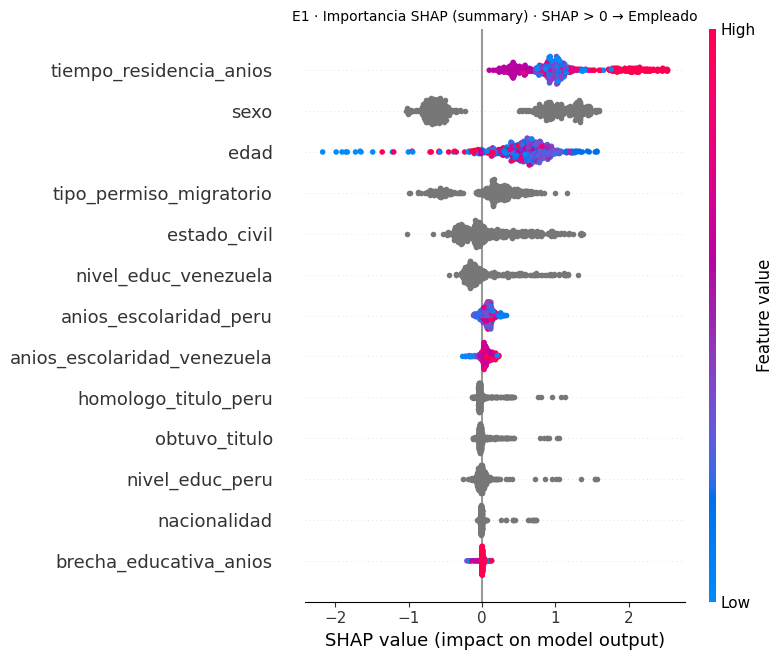

In [ ]:
# Gráfico 1: Etapa 1 - Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_e1, X_sample_e1, show=False)
plt.title(f'E1 · Importancia SHAP (summary) · {SIGNO["E1"]}', fontsize=10)
plt.tight_layout()
plt.savefig('resultados_xai/a3_1_e1_summary.png', dpi=150, bbox_inches='tight')
plt.show()

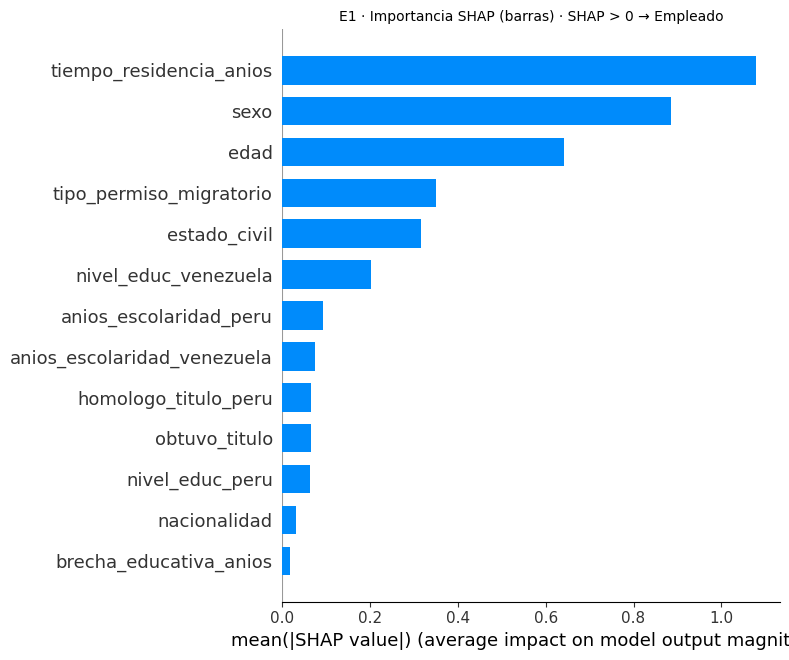

In [ ]:
# Gráfico 2: Etapa 1 - Gráfico de Barras
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_e1, X_sample_e1, plot_type='bar', show=False)
plt.title(f'E1 · Importancia SHAP (barras) · {SIGNO["E1"]}', fontsize=10)
plt.tight_layout()
plt.savefig('resultados_xai/a3_1_e1_barras.png', dpi=150, bbox_inches='tight')
plt.show()

Etapa 2: Gráfico de Resumen

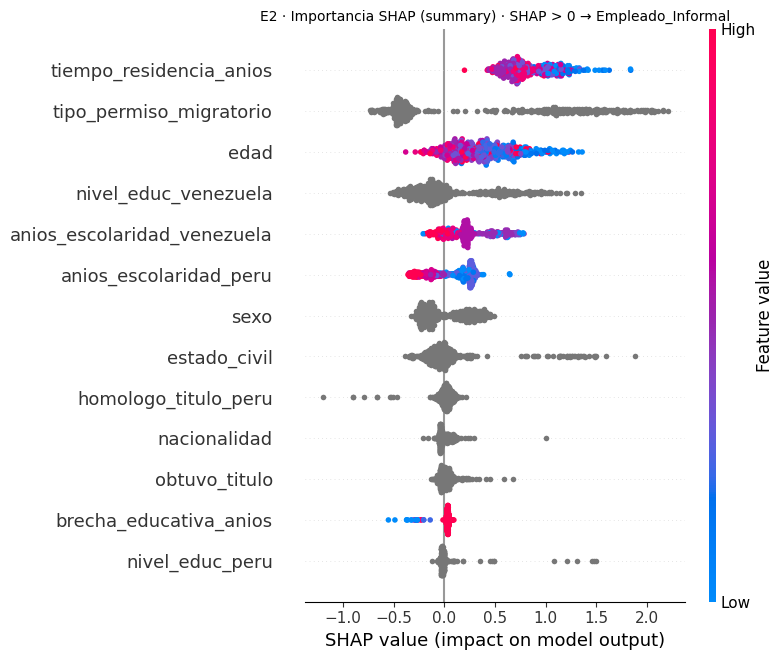

In [ ]:
# Gráfico 3: Etapa 2 - Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_e2, X_sample_e2, show=False)
plt.title(f'E2 · Importancia SHAP (summary) · {SIGNO["E2"]}', fontsize=10)
plt.tight_layout()
plt.savefig('resultados_xai/a3_1_e2_summary.png', dpi=150, bbox_inches='tight')
plt.show()

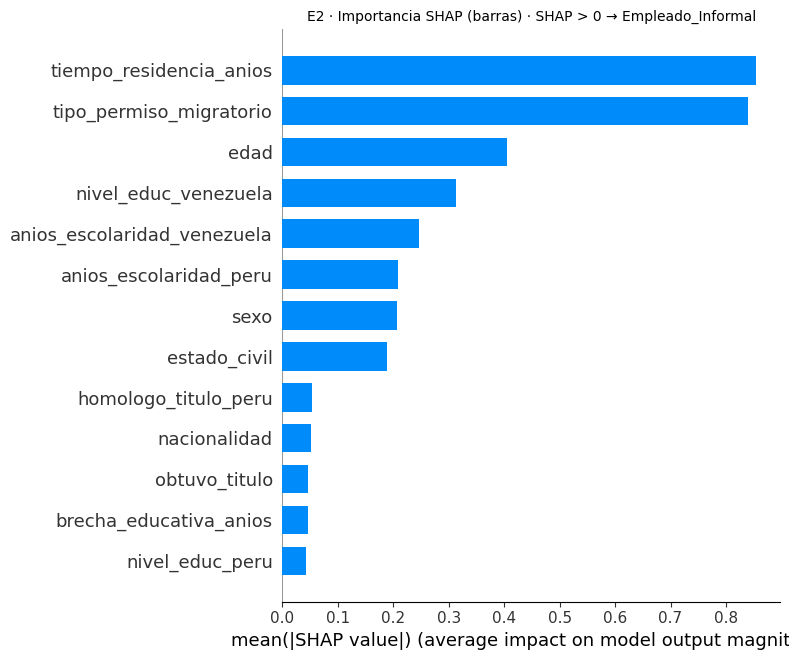

In [ ]:
# Gráfico 4: Etapa 2 - Gráfico de Barras
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_e2, X_sample_e2, plot_type='bar', show=False)
plt.title(f'E2 · Importancia SHAP (barras) · {SIGNO["E2"]}', fontsize=10)
plt.tight_layout()
plt.savefig('resultados_xai/a3_1_e2_barras.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def tabla_efecto(sv, Xs, modelo, etapa, min_n=20):
    c_neg, c_pos = modelo.classes_[0], modelo.classes_[1]
    filas = []
    for col in cat_cols:
        j = Xs.columns.get_loc(col)
        g = (pd.DataFrame({'cat': Xs[col].map(_norm).values, 'shap': sv[:, j]})
               .groupby('cat')['shap'].agg(['mean', 'count']))
        for cat, r in g.iterrows():
            ok = r['count'] >= min_n
            m = float(r['mean'])
            filas.append({
                'Etapa': etapa, 'Variable': col, 'Código': cat or '(vacío)', 'Categoría': etiqueta(col, cat),
                'n': int(r['count']), 'SHAP medio': round(m, 3),
                'Dirección': ('hacia ' + (c_pos if m > 0 else c_neg)) if ok else 'n insuficiente',
                'Magnitud': (('alta' if abs(m) >= 0.5 else 'media' if abs(m) >= 0.2 else 'baja') if ok else '—'),
            })
    return pd.DataFrame(filas)

efecto_e1 = tabla_efecto(shap_values_e1, X_sample_e1, cat_model_e1, 'E1')
efecto_e2 = tabla_efecto(shap_values_e2, X_sample_e2, cat_model_e2, 'E2')
tabla_efectos = pd.concat([efecto_e1, efecto_e2], ignore_index=True)
tabla_efectos.to_csv('resultados_xai/a3_2_efecto_por_categoria.csv', index=False)

CLAVE = [c for c in ['tipo_permiso_migratorio', 'obtuvo_titulo', 'homologo_titulo_peru',
                     'nivel_educ_peru', 'nivel_educ_venezuela'] if c in cat_cols]
for etapa, t in (('E1', efecto_e1), ('E2', efecto_e2)):
    print(f'\n===== {etapa} · variables clave ({SIGNO[etapa]}) =====')
    display(t[t.Variable.isin(CLAVE)].drop(columns='Etapa').reset_index(drop=True))

def cruce(a, b):
    t = pd.crosstab(df[a].map(lambda v: etiqueta(a, v)), df[b].map(lambda v: etiqueta(b, v)))
    return t

pares = [('nivel_educ_venezuela', 'nivel_educ_peru'), ('obtuvo_titulo', 'homologo_titulo_peru'),
         ('nivel_educ_venezuela', 'obtuvo_titulo')]
for a, b in [(a, b) for a, b in pares if a in df.columns and b in df.columns]:
    print(f'\n--- {a} × {b} (conteos) ---'); display(cruce(a, b))


===== E1 · variables clave (SHAP > 0 → Empleado) =====


,Variable,Código,Categoría,n,SHAP medio,Dirección,Magnitud
0,nivel_educ_venezuela,1,Sin nivel,28,0.024,hacia Empleado,baja
1,nivel_educ_venezuela,10,Universitaria completa,70,-0.022,hacia Desempleado,baja
2,nivel_educ_venezuela,11,Maestría/Doctorado,2,1.216,n insuficiente,—
3,nivel_educ_venezuela,3,Básica incompleta,22,-0.048,hacia Desempleado,baja
4,nivel_educ_venezuela,4,Básica completa,35,0.096,hacia Empleado,baja
5,nivel_educ_venezuela,5,Media diversificada incompleta,77,-0.131,hacia Desempleado,baja
6,nivel_educ_venezuela,6,Media diversificada completa,175,-0.169,hacia Desempleado,baja
7,nivel_educ_venezuela,7,Técnico superior incompleta,13,0.404,n insuficiente,—
8,nivel_educ_venezuela,8,Técnico superior completa,44,0.753,hacia Empleado,alta
9,nivel_educ_venezuela,9,Universitaria incompleta,34,-0.063,hacia Desempleado,baja



===== E2 · variables clave (SHAP > 0 → Empleado_Informal) =====


,Variable,Código,Categoría,n,SHAP medio,Dirección,Magnitud
0,nivel_educ_venezuela,1,Sin nivel,18,-0.294,n insuficiente,—
1,nivel_educ_venezuela,10,Universitaria completa,66,-0.343,hacia Empleado_Formal,media
2,nivel_educ_venezuela,11,Maestría/Doctorado,5,0.002,n insuficiente,—
3,nivel_educ_venezuela,3,Básica incompleta,17,0.891,n insuficiente,—
4,nivel_educ_venezuela,4,Básica completa,29,0.559,hacia Empleado_Informal,alta
5,nivel_educ_venezuela,5,Media diversificada incompleta,78,0.651,hacia Empleado_Informal,alta
6,nivel_educ_venezuela,6,Media diversificada completa,180,-0.081,hacia Empleado_Formal,baja
7,nivel_educ_venezuela,7,Técnico superior incompleta,18,0.580,n insuficiente,—
8,nivel_educ_venezuela,8,Técnico superior completa,43,-0.189,hacia Empleado_Formal,baja
9,nivel_educ_venezuela,9,Universitaria incompleta,46,-0.185,hacia Empleado_Formal,baja



--- nivel_educ_venezuela × nivel_educ_peru (conteos) ---


nivel_educ_peru,Básica especial,Inicial,Maestría/Doctorado,No ha estudiado en el Perú,Primaria completa,Primaria incompleta,Secundaria completa,Secundaria incompleta,Sin dato,Sin nivel,Superior no univ. completa,Superior no univ. incompleta,Superior univ. completa,Superior univ. incompleta
nivel_educ_venezuela,,,,,,,,,,,,,,
Básica completa,0,0,0,761,4,0,19,21,0,0,0,0,0,1
Básica incompleta,0,0,0,427,6,7,12,18,0,0,0,0,0,0
Maestría/Doctorado,0,0,2,75,0,0,0,0,0,0,0,0,0,0
Media diversificada completa,0,0,0,3594,0,0,16,0,0,0,2,5,1,20
Media diversificada incompleta,0,0,0,1578,0,0,65,43,0,0,0,0,0,0
Preescolar,0,0,0,4,0,1,0,0,0,0,0,0,0,0
Sin dato,0,0,0,0,0,0,0,0,2,0,0,0,0,0
Sin nivel,3,1,3,38,10,16,217,115,0,4,52,39,57,36
Técnico superior completa,0,0,0,1078,0,0,0,0,0,0,8,0,0,1



--- obtuvo_titulo × homologo_titulo_peru (conteos) ---


homologo_titulo_peru,No,No aplica / sin dato,Sí
obtuvo_titulo,,,
No,0,210,0
No aplica / sin dato,0,9123,0
Sí,1968,0,177



--- nivel_educ_venezuela × obtuvo_titulo (conteos) ---


obtuvo_titulo,No,No aplica / sin dato,Sí
nivel_educ_venezuela,,,
Básica completa,0,806,0
Básica incompleta,0,470,0
Maestría/Doctorado,2,2,73
Media diversificada completa,0,3638,0
Media diversificada incompleta,0,1686,0
Preescolar,0,5,0
Sin dato,0,2,0
Sin nivel,0,591,0
Técnico superior completa,61,507,519


4. Diferencia de Paridad Demográfica (DPD)

In [ ]:
from fairlearn.metrics import MetricFrame, demographic_parity_difference

pred_e1_test = cat_model_e1.predict(X_test).ravel()
y_test_e1 = y_test.apply(lambda x: 'Desempleado' if x == 'Desempleado' else 'Empleado')

dpd = demographic_parity_difference(
    y_true=(y_test_e1 == 'Desempleado').astype(int),
    y_pred=(pred_e1_test == 'Desempleado').astype(int),
    sensitive_features=X_test['sexo']
)
print(f"Diferencia de Paridad Demográfica (sexo, Etapa 1): {dpd:.3f}")

Diferencia de Paridad Demográfica (sexo, Etapa 1): 0.146


In [ ]:
mask_test_emp = y_test != 'Desempleado'
X_test_emp = X_test[mask_test_emp]
y_test_e2 = y_test[mask_test_emp]

pred_e2_raw = cat_model_e2.predict(X_test_emp).ravel()

dpd_sexo_e2 = demographic_parity_difference(
    y_true=(y_test_e2 == 'Empleado_Informal').astype(int),
    y_pred=(pred_e2_raw == 'Empleado_Informal').astype(int),
    sensitive_features=X_test_emp['sexo']
)
print(f"DPD (sexo, Etapa 2): {dpd_sexo_e2:.3f}")

DPD (sexo, Etapa 2): 0.096


In [ ]:
print(pd.crosstab(X_test['sexo'], y_test_e1))

condicion_laboral  Desempleado  Empleado
sexo                                    
1                           81      1143
2                          162       910


5. Explicaciones individuales


=== E1 · perfil #4 · predicho: Desempleado ===
P(Empleado) = sigmoide(-0.299 + Σ SHAP) = sigmoide(-2.568) = 0.0712   | umbral de decisión (log-odds) = 0.000


,variable,valor,SHAP (log-odds),empuja hacia
0,edad,15.0,-1.854,Desempleado
1,tiempo_residencia_anios,1.0,0.823,Empleado
2,tipo_permiso_migratorio,No cuenta con permiso migratorio,-0.648,Desempleado
3,sexo,Mujer,-0.523,Desempleado
4,estado_civil,Soltero/a,0.296,Empleado
5,nivel_educ_venezuela,Media diversificada incompleta,-0.174,Desempleado


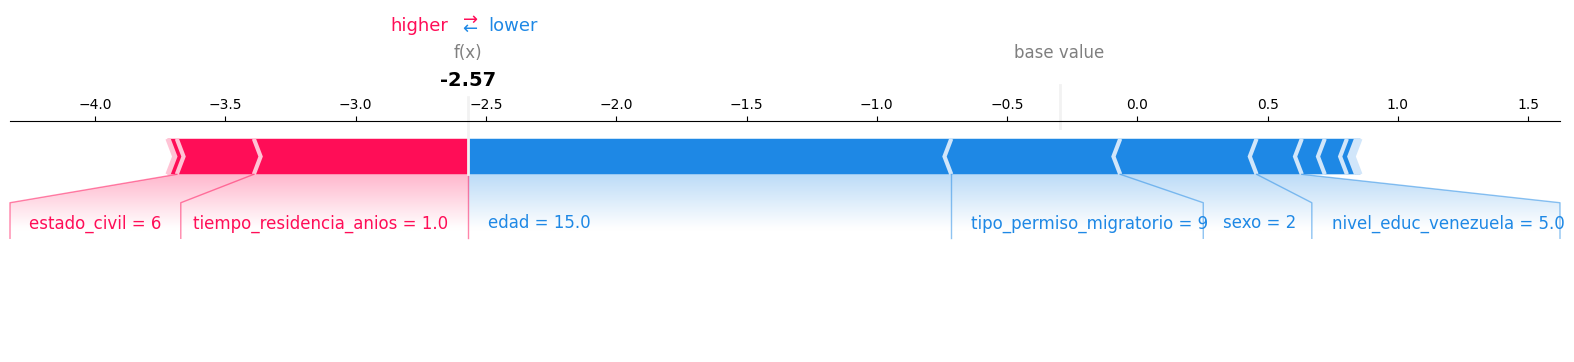


=== E1 · perfil #0 · predicho: Empleado ===
P(Empleado) = sigmoide(-0.299 + Σ SHAP) = sigmoide(4.550) = 0.9895   | umbral de decisión (log-odds) = 0.000


,variable,valor,SHAP (log-odds),empuja hacia
0,sexo,Hombre,1.110,Empleado
1,edad,50.0,0.843,Empleado
2,tiempo_residencia_anios,5.0,0.788,Empleado
3,nacionalidad,Colombiano/a,0.680,Empleado
4,tipo_permiso_migratorio,Residencia (carné de extranjería),0.366,Empleado
5,anios_escolaridad_peru,9.0,0.311,Empleado


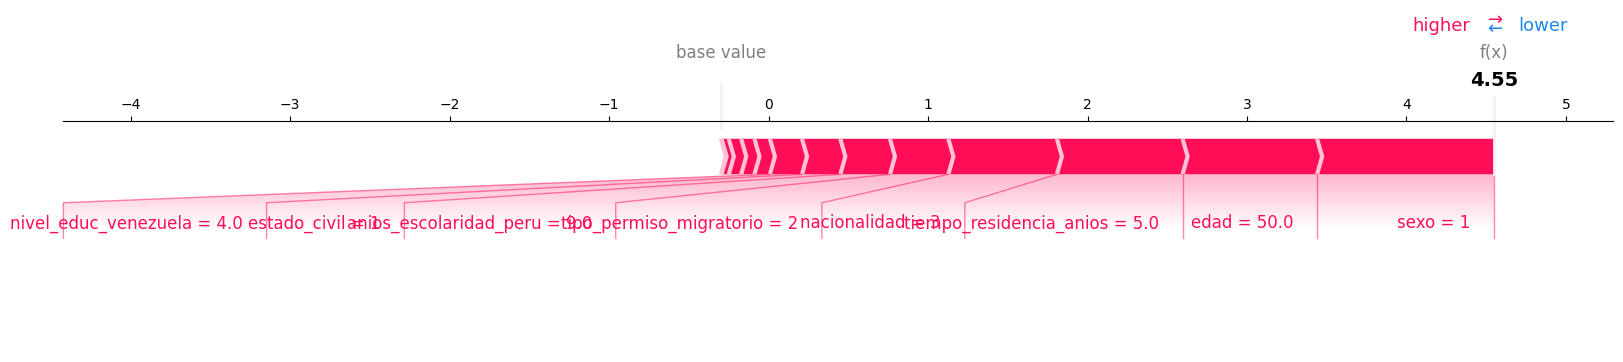


=== E2 · perfil #3 · predicho: Empleado_Formal ===
P(Empleado_Informal) = sigmoide(-0.196 + Σ SHAP) = sigmoide(-0.339) = 0.4159   | umbral de decisión (log-odds) = 0.470


,variable,valor,SHAP (log-odds),empuja hacia
0,tiempo_residencia_anios,4.0,0.708,Empleado_Informal
1,tipo_permiso_migratorio,Residencia (carné de extranjería),-0.470,Empleado_Formal
2,edad,29.0,0.415,Empleado_Informal
3,nivel_educ_venezuela,Técnico superior completa,-0.262,Empleado_Formal
4,anios_escolaridad_peru,14.0,-0.241,Empleado_Formal
5,sexo,Hombre,-0.208,Empleado_Formal


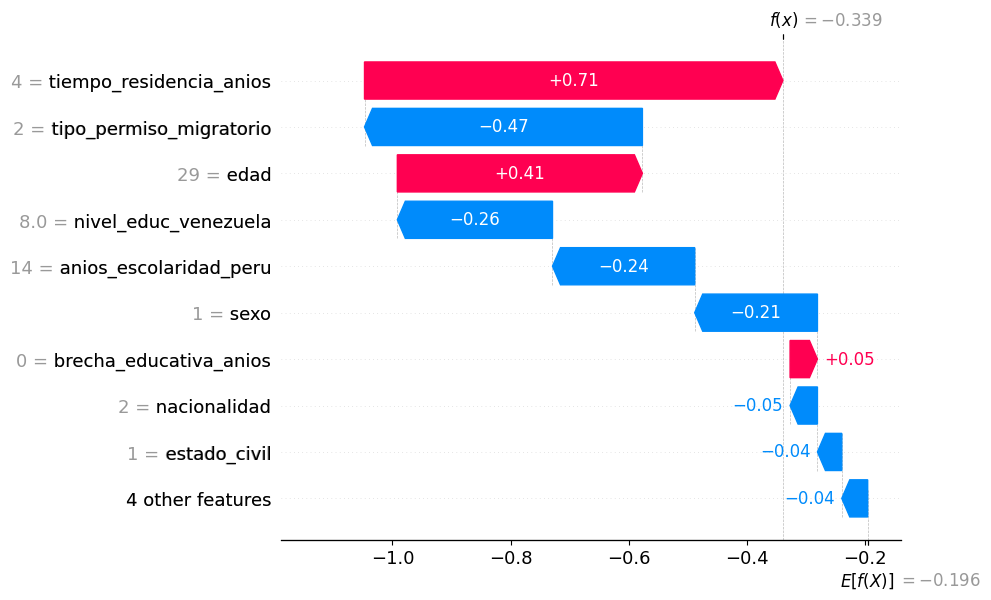


=== E2 · perfil #0 · predicho: Empleado_Informal ===
P(Empleado_Informal) = sigmoide(-0.196 + Σ SHAP) = sigmoide(1.237) = 0.7750   | umbral de decisión (log-odds) = 0.470


,variable,valor,SHAP (log-odds),empuja hacia
0,tiempo_residencia_anios,6.0,0.769,Empleado_Informal
1,nivel_educ_venezuela,Técnico superior incompleta,0.662,Empleado_Informal
2,tipo_permiso_migratorio,Residencia (carné de extranjería),-0.453,Empleado_Formal
3,sexo,Mujer,0.411,Empleado_Informal
4,estado_civil,Conviviente,-0.067,Empleado_Formal
5,edad,35.0,0.062,Empleado_Informal


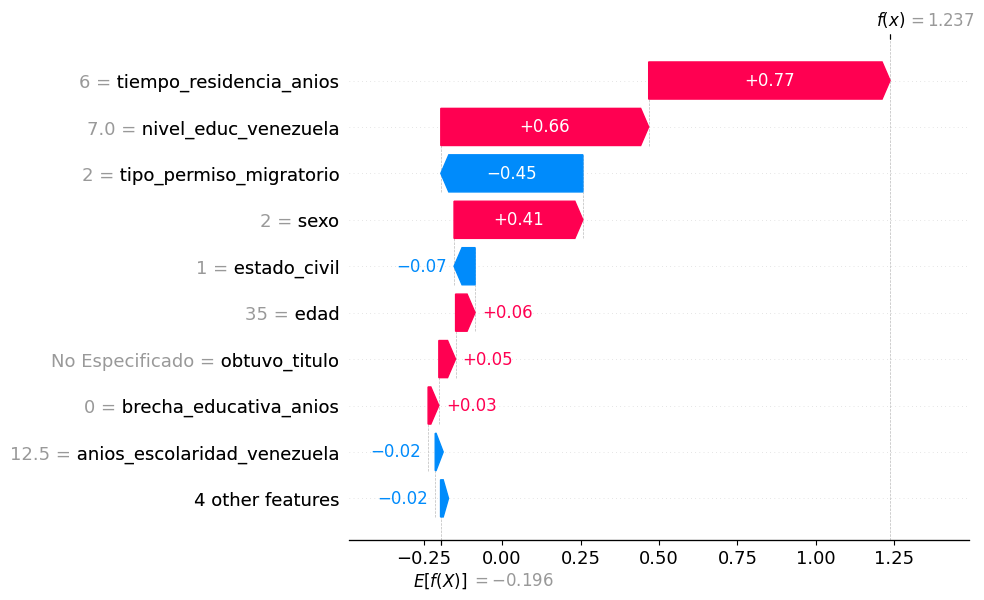

,Etapa,Índice en la muestra,Clase predicha,P(clase +),Clase +,Log-odds,Umbral,Top-3 factores
0,E1,4,Desempleado,0.0712,Empleado,-2.568,0.00,edad=15.0 (-1.85); tiempo_residencia_anios=1.0 (+0.82); tipo_permiso_migratorio=No cuenta con permiso migratorio (-0.65)
1,E1,0,Empleado,0.9895,Empleado,4.550,0.00,sexo=Hombre (+1.11); edad=50.0 (+0.84); tiempo_residencia_anios=5.0 (+0.79)
2,E2,3,Empleado_Formal,0.4159,Empleado_Informal,-0.339,0.47,tiempo_residencia_anios=4.0 (+0.71); tipo_permiso_migratorio=Residencia (carné de extranjería) (-0.47); edad=29.0 (+0.41)
3,E2,0,Empleado_Informal,0.7750,Empleado_Informal,1.237,0.47,tiempo_residencia_anios=6.0 (+0.77); nivel_educ_venezuela=Técnico superior incompleta (+0.66); tipo_permiso_migratorio=Residencia (carné de extranjería) (-0.45)


In [ ]:
def explicar_local(Xs, sv, i, modelo, explainer, peso_clase_neg=None, top=6):
    c_neg, c_pos = list(modelo.classes_)
    base = float(np.ravel(explainer.expected_value)[0])
    fila = Xs.iloc[[i]]
    logit = base + float(sv[i].sum())
    logit_modelo = float(modelo.predict(fila, prediction_type='RawFormulaVal')[0])
    assert abs(logit - logit_modelo) < 1e-3, f'SHAP no suma al log-odds del modelo ({logit} vs {logit_modelo})'
    p_pos = float(1 / (1 + np.exp(-logit)))
    umbral = 0.0 if peso_clase_neg is None else float(np.log(peso_clase_neg))
    pred = c_pos if logit > umbral else c_neg

    contrib = pd.DataFrame({
        'variable': Xs.columns,
        'valor': [etiqueta(c, fila[c].iloc[0]) if c in cat_cols else round(float(fila[c].iloc[0]), 2) for c in Xs.columns],
        'SHAP (log-odds)': sv[i].round(3),
    })
    contrib['empuja hacia'] = np.where(contrib['SHAP (log-odds)'] > 0, c_pos, c_neg)
    contrib = contrib.reindex(contrib['SHAP (log-odds)'].abs().sort_values(ascending=False).index).head(top)
    return {'base': base, 'logit': logit, 'umbral': umbral, 'p_pos': p_pos, 'clase_pos': c_pos,
            'pred': pred, 'tabla': contrib.reset_index(drop=True)}

pred_s1 = cat_model_e1.predict(X_sample_e1).ravel()
w_e2 = np.array([peso_formal if c == 'Empleado_Formal' else 1.0 for c in cat_model_e2.classes_])
pred_s2 = np.array(cat_model_e2.classes_)[(cat_model_e2.predict_proba(X_sample_e2) * w_e2).argmax(axis=1)]
def primero(pred, clase):
    idx = np.where(pred == clase)[0]
    return int(idx[0]) if len(idx) else None

perfiles_locales = [(e, c, primero(p, c)) for e, c, p in (
    ('E1', 'Desempleado', pred_s1), ('E1', 'Empleado', pred_s1),
    ('E2', 'Empleado_Formal', pred_s2), ('E2', 'Empleado_Informal', pred_s2))]
perfiles_locales = [(e, c, i) for e, c, i in perfiles_locales if i is not None]

resumen_locales = []
for etapa, clase, i in perfiles_locales:
    if etapa == 'E1':
        info = explicar_local(X_sample_e1, shap_values_e1, i, cat_model_e1, explainer_e1)
    else:
        info = explicar_local(X_sample_e2, shap_values_e2, i, cat_model_e2, explainer_e2, peso_clase_neg=peso_formal)
    print(f"\n=== {etapa} · perfil #{i} · predicho: {info['pred']} ===")
    print(f"P({info['clase_pos']}) = sigmoide({info['base']:.3f} + Σ SHAP) = sigmoide({info['logit']:.3f}) = {info['p_pos']:.4f}"
          f"   | umbral de decisión (log-odds) = {info['umbral']:.3f}")
    display(info['tabla'])
    resumen_locales.append({'Etapa': etapa, 'Índice en la muestra': i, 'Clase predicha': info['pred'],
                            f'P(clase +)': round(info['p_pos'], 4), 'Clase +': info['clase_pos'],
                            'Log-odds': round(info['logit'], 3), 'Umbral': round(info['umbral'], 3),
                            'Top-3 factores': '; '.join(f"{r.variable}={r.valor} ({r._3:+.2f})" for r in info['tabla'].head(3).itertuples())})

    if etapa == 'E1':
        shap.force_plot(info['base'], shap_values_e1[i], X_sample_e1.iloc[i], matplotlib=True, show=False)
    else:
        shap.plots.waterfall(shap.Explanation(values=shap_values_e2[i], base_values=info['base'],
                                              data=X_sample_e2.iloc[i], feature_names=X_sample_e2.columns.tolist()),
                             max_display=10, show=False)
    plt.savefig(f'resultados_xai/a3_3_{etapa.lower()}_{clase}.png', dpi=150, bbox_inches='tight')
    plt.show()

perfiles_explicados = pd.DataFrame(resumen_locales)
display(perfiles_explicados)
perfiles_explicados.to_csv('resultados_xai/a3_3_perfiles_explicados.csv', index=False)

6. Motor de recomendaciones con perfiles reales

In [ ]:
REGLAS = {
    'R1': {
        'texto': "Inicia el trámite de regularización migratoria en MIGRACIONES. "
                 "Necesitarás: solicitud (declaración jurada), número y fecha del "
                 "recibo de pago, copia de tu documento de identidad vigente, y "
                 "copia de un recibo de servicio público de tu domicilio. Consultas: (01) 200 1000."
    },
    'R2': {
        'texto': "Si eres solicitante de refugio, tu carné y autorización de trabajo ya "
                 "te permiten trabajar legalmente. Consulta en el MRE: (01) 204-3127 o "
                 "solicitantesrefugio@rree.gob.pe."
    },
    'R3': {
        'texto': "Tu Carné de Extranjería te habilita para firmar contratos laborales "
                 "y es aceptado tanto en la Bolsa de Trabajo (Empleos Perú) como para "
                 "tramitar tu RUC."
    },
    'R4': {
        'texto': "Tu Permiso Temporal de Permanencia (CPP/PTP) es un documento habilitante "
                 "para trabajar, y es aceptado en la Bolsa de Trabajo, en Capacita-T, en "
                 "SUNAFIL y para tramitar tu RUC."
    },
    'R5': {
        'texto': "Con pasaporte y calidad migratoria temporal, solo la calidad 'temporal "
                 "trabajador' te permite firmar contratos directamente; las demás calidades "
                 "requieren un permiso especial. Confirma tu situación exacta en MIGRACIONES."
    },
    'R6': {
        'texto': "Recibe orientación gratuita y sin requisitos en el Servicio de Orientación "
                 "para el Migrante (SOM): de forma presencial en cualquiera de los 45 Centros "
                 "de Empleo a nivel nacional, por el 0800-16872, o por orientacionmigrante@trabajo.gob.pe."
    },

    'R7': {
        'texto': "Inicia el trámite de RECONOCIMIENTO de tu título universitario ante "
                 "SUNEDU: se evalúa en máximo 30 días hábiles, cuesta S/400, y puedes "
                 "hacerlo de forma presencial o virtual. Necesitas el diploma original "
                 "con acceso a base de datos verificable, o Apostilla de La Haya/legalización, "
                 "más el comprobante de pago."
    },
    'R8': {
        'texto': "Si tu título es de instituto (técnico), no corresponde reconocimiento "
                 "sino REGISTRO ante el MINEDU: solicitud, título con apostilla o "
                 "legalización, traducción si no está en castellano, declaración jurada y pago."
    },
    'R9': {
        'texto': "Reconocimiento y revalidación son trámites distintos — no son lo mismo. "
                 "Si tu título es de abogacía, corresponde revalidación directa en una "
                 "universidad peruana autorizada."
    },
    'R10': {
        'texto': "Si tu profesión es regulada (medicina, enfermería, etc.), consulta antes "
                 "con el colegio profesional correspondiente — es quien decide si exige "
                 "revalidación adicional al reconocimiento de SUNEDU."
    },
    'R11': {
        'texto': "La revalidación u homologación de tu título se realiza en universidades "
                 "peruanas autorizadas por SUNEDU — cada una fija sus propios requisitos, "
                 "costos y plazos."
    },
    'R12': {
        'texto': "Una vez reconocido tu título, solicita la constancia de inscripción y "
                 "verifica tu registro en línea. Ten en cuenta que el reconocimiento habilita "
                 "docencia universitaria e investigación, pero no el ejercicio profesional "
                 "(eso depende del colegio profesional)."
    },
    'R13': {
        'texto': "Completa tu perfil en la Bolsa de Trabajo de Empleos Perú y mejora tu CV "
                 "con el Servicio de Asesoría para la Búsqueda de Empleo (ABE), disponible "
                 "en tu Centro de Empleo más cercano."
    },
    'R14': {
        'texto': "Para consultas sobre tu trámite de reconocimiento, escribe a "
                 "consultasreconocimiento@sunedu.gob.pe o consultasgradosytitulos@sunedu.gob.pe."
    },
    'R15': {
        'texto': "Si tienes estudios superiores pero no obtuviste el título: gestiona la "
                 "obtención del diploma con la institución donde estudiaste (sin él no puedes "
                 "iniciar el reconocimiento), o considera completar tus estudios en una "
                 "universidad o instituto licenciado en Perú — consulta en tuni.pe o el portal Mi Carrera."
    },
    'R16': {
        'texto': "Certifica gratuitamente lo que ya sabes hacer: Capacita-T ofrece más de "
                 "50 cursos con certificación gratuita en 12 rutas de aprendizaje (análisis "
                 "de datos, habilidades digitales, gestión de negocios, entre otras)."
    },
    'R17': {
        'texto': "Explora rutas de formación accesibles según tu nivel actual: CETPRO "
                 "(ciclo auxiliar sin requisito previo, ciclo técnico con primaria completa), "
                 "institutos tecnológicos (secundaria completa + examen de admisión), o "
                 "universidad pública gratuita (secundaria completa + admisión)."
    },

    'R18': {
        'texto': "Si estudiaste primaria o secundaria en Venezuela y no tiene equivalencia "
                 "reconocida en Perú, convalídala o revalídala ante el MINEDU — Venezuela está "
                 "cubierta por el Convenio Andrés Bello. Necesitarás certificados legalizados "
                 "o apostillados y traducción si corresponde; hay vía virtual disponible."
    },
    'R20': {
        'texto': "Con un nivel educativo alto en Venezuela pero sin reconocer en Perú, "
                 "prioriza la ruta de reconocimiento de título (ver recomendaciones de "
                 "SUNEDU) — es la palanca más directa para acceder a empleo formal acorde "
                 "a tu formación."
    },
    'R21': {
        'texto': "Con tu nivel educativo ya reconocido en Perú, el siguiente paso es "
                 "enfocarte en la búsqueda activa de empleo acorde a tu formación."
    },

    'R22': {
        'texto': "La formalización laboral mejora directamente el nivel de ingresos: entre "
                 "la población migrante venezolana en Perú, quienes trabajan en dependencia "
                 "formal ganan en promedio S/993, mientras que los empleadores formalizados "
                 "llegan a S/2,553."
    },
    'R23': {
        'texto': "Regístrate en la Bolsa de Trabajo de Empleos Perú — requiere ser mayor de "
                 "edad, tener CE o CPP, y estar habilitado para trabajar."
    },
    'R24': {
        'texto': "Conoce tus derechos laborales y, si los necesitas, presenta consultas en "
                 "SUNAFIL Responde o denuncias confidenciales (necesitarás el RUC de la "
                 "empresa, su dirección, y boletas o contrato)."
    },

    'R25': {
        'texto': "Si trabajas de forma independiente, inscríbete en el RUC como persona "
                 "natural (trámite presencial en un Centro de Servicios al Contribuyente o "
                 "MAC): necesitas DNI, CE, CPP o pasaporte con calidad migratoria habilitante. "
                 "Luego activa tu RUC y solicita tu Clave SOL."
    },
    'R26': {
        'texto': "Emite tus Recibos por Honorarios de forma electrónica (obligatorio desde "
                 "2017): necesitas RUC con rentas de cuarta categoría y tu Clave SOL."
    },
    'R27': {
        'texto': "Recuerda registrar los pagos que recibas hasta el décimo día hábil del mes "
                 "siguiente; si el pago es a crédito, las cuotas se pueden modificar dentro "
                 "de los 10 días hábiles siguientes."
    },
    'R29': {
        'texto': "Si piensas emprender un negocio propio, el MTPE ofrece orientación gratuita "
                 "para el emprendimiento (0800-16872, orientacionemprendimiento@trabajo.gob.pe), "
                 "y PRODUCE ofrece el servicio 'Crea tu empresa' para formalizarlo."
    },
}

7. Tabla de variables accionables / no accionables

In [ ]:
ACC, PAR, NO = 'Accionable', 'Parcialmente accionable', 'No accionable'
filas = [
 ('tipo_permiso_migratorio', ACC, 'Se regulariza o cambia mediante trámites ante Migraciones y condiciona la firma de contratos.', 'Sí (R1–R5, prioridad por SHAP)'),
 ('obtuvo_titulo',           ACC, 'La persona puede gestionar el diploma con su institución de origen.', 'Sí (R7, R8, R15, R16; prioridad por SHAP)'),
 ('homologo_titulo_peru',    ACC, 'El reconocimiento o la revalidación del título son trámites concretos (SUNEDU, MINEDU, universidades).', 'Sí (R7–R14; prioridad por SHAP)'),
 ('nivel_educ_peru',         PAR, 'El nivel reconocido en Perú sube con reconocimiento, convalidación o estudiando en Perú; es de mediano plazo.', 'Sí (condiciona R7–R21)'),
 ('anios_escolaridad_peru',  PAR, 'Se acumula estudiando en Perú; no se modifica de inmediato.', 'No'),
 ('brecha_educativa_anios',  PAR, 'Variable derivada: disminuye cuando se reconoce la formación previa; no se actúa sobre ella directamente.', 'No'),
 ('nivel_educ_venezuela',    NO,  'Es un dato histórico; lo modificable es su reconocimiento en Perú, no el nivel en sí.', 'Sí (condiciona R7–R21, como dato de entrada)'),
 ('anios_escolaridad_venezuela', NO, 'Dato histórico, no modificable.', 'No'),
 ('tiempo_residencia_anios', NO,  'Solo transcurre; no es una decisión de la persona.', 'No'),
 ('sexo',                    NO,  'Característica personal protegida; recomendar a partir de ella sería discriminatorio. Se audita en A3.10.', 'No'),
 ('edad',                    NO,  'No modificable; no se usa para recomendar.', 'No'),
 ('nacionalidad',            NO,  'Característica personal protegida.', 'No'),
 ('estado_civil',            NO,  'Característica personal; no se usa para recomendar.', 'No'),
]
filas = [f for f in filas if f[0] in (cat_cols + num_cols)]
tabla_accionables = pd.DataFrame(filas, columns=['Variable', 'Clasificación', 'Justificación', 'Usada por el motor de reglas'])
tabla_accionables = (tabla_accionables
    .merge(rank_e1[['variable', 'ranking']].rename(columns={'variable': 'Variable', 'ranking': 'Ranking SHAP E1'}), on='Variable', how='left')
    .merge(rank_e2[['variable', 'ranking']].rename(columns={'variable': 'Variable', 'ranking': 'Ranking SHAP E2'}), on='Variable', how='left'))
falta = set(cat_cols + num_cols) - set(tabla_accionables.Variable)
assert not falta, f'Falta clasificar estas variables en la tabla: {falta}'
tabla_accionables = tabla_accionables[tabla_accionables.Variable.isin(cat_cols + num_cols)].reset_index(drop=True)
display(tabla_accionables)
tabla_accionables.to_csv('resultados_xai/a3_4_variables_accionables.csv', index=False)
print('\nResumen:'); display(tabla_accionables.Clasificación.value_counts().to_frame('n_variables'))

,Variable,Clasificación,Justificación,Usada por el motor de reglas,Ranking SHAP E1,Ranking SHAP E2
0,tipo_permiso_migratorio,Accionable,Se regulariza o cambia mediante trámites ante Migraciones y condiciona la firma de contratos.,"Sí (R1–R5, prioridad por SHAP)",4,2
1,obtuvo_titulo,Accionable,La persona puede gestionar el diploma con su institución de origen.,"Sí (R7, R8, R15, R16; prioridad por SHAP)",10,11
2,homologo_titulo_peru,Accionable,"El reconocimiento o la revalidación del título son trámites concretos (SUNEDU, MINEDU, universidades).",Sí (R7–R14; prioridad por SHAP),9,9
3,nivel_educ_peru,Parcialmente accionable,"El nivel reconocido en Perú sube con reconocimiento, convalidación o estudiando en Perú; es de mediano plazo.",Sí (condiciona R7–R21),11,13
4,anios_escolaridad_peru,Parcialmente accionable,Se acumula estudiando en Perú; no se modifica de inmediato.,No,7,6
5,brecha_educativa_anios,Parcialmente accionable,Variable derivada: disminuye cuando se reconoce la formación previa; no se actúa sobre ella directamente.,No,13,12
6,nivel_educ_venezuela,No accionable,"Es un dato histórico; lo modificable es su reconocimiento en Perú, no el nivel en sí.","Sí (condiciona R7–R21, como dato de entrada)",6,4
7,anios_escolaridad_venezuela,No accionable,"Dato histórico, no modificable.",No,8,5
8,tiempo_residencia_anios,No accionable,Solo transcurre; no es una decisión de la persona.,No,1,1
9,sexo,No accionable,Característica personal protegida; recomendar a partir de ella sería discriminatorio. Se audita en A3.10.,No,2,7



Resumen:


,n_variables
Clasificación,
No accionable,7
Accionable,3
Parcialmente accionable,3


8. Probar el motor de recomendaciones con perfiles reales

In [ ]:
AREAS = {
    'A1': 'Regularización y documentos migratorios',
    'A2': 'Reconocimiento de estudios y títulos',
    'A3': 'Formación y certificación',
    'A4': 'Orientación y búsqueda de empleo',
    'A5': 'Derechos laborales, formalización y emprendimiento',
}
VP, VT, VH = 'tipo_permiso_migratorio', 'obtuvo_titulo', 'homologo_titulo_peru'
TIT = 'obtuvo_titulo=1 ∧ homologo=2'
def _m(area, cond, aplica='Todas', var=''):
    return {'area_id': area, 'area': AREAS[area], 'activa_cuando': cond, 'aplica_a': aplica, 'variable_prioridad': var}

META_REGLAS = {
 'R1':  _m('A1', 'permiso ∈ {6,7,8,9}', var=VP),
 'R2':  _m('A1', '⚠ sin condición definida (hoy no se activa)', var=VP),
 'R3':  _m('A1', 'permiso = 2', var=VP),
 'R4':  _m('A1', 'permiso = 1', var=VP),
 'R5':  _m('A1', 'permiso = 3', var=VP),
 'R6':  _m('A4', 'siempre'),
 'R7':  _m('A2', TIT + ' ∧ (universitario en Perú ∨ en Venezuela)', var=VT),
 'R8':  _m('A2', TIT + ' ∧ técnico superior (y ninguno universitario)', var=VT),
 'R9':  _m('A2', TIT + ' ∧ (universitario en Perú ∨ en Venezuela)'),
 'R10': _m('A2', TIT + ' ∧ (universitario en Perú ∨ en Venezuela)'),
 'R11': _m('A2', TIT, var=VH),
 'R12': _m('A2', TIT + ' ∧ (universitario en Perú ∨ en Venezuela)', var=VH),
 'R13': _m('A4', TIT + ' ∨ clase ∈ {Desempleado, Informal}'),
 'R14': _m('A2', TIT + ' ∧ (universitario en Perú ∨ en Venezuela)', var=VH),
 'R15': _m('A2', 'obtuvo_titulo=2 ∧ (estudios superiores en Perú ∨ en Venezuela)', var=VT),
 'R16': _m('A3', 'obtuvo_titulo=2 ∧ (estudios superiores en Perú ∨ en Venezuela)'),
 'R17': _m('A3', 'sin estudios superiores en Perú ni en Venezuela (si no entra en las ramas anteriores)'),
 'R18': _m('A2', 'universitario en Venezuela ∧ sin estudios superiores en Perú'),
 'R20': _m('A2', 'universitario en Venezuela ∧ sin estudios superiores en Perú'),
 'R21': _m('A4', 'universitario en Perú (si no se cumple la condición de R18/R20)'),
 'R22': _m('A5', 'clase = Informal', 'Empleado_Informal'),
 'R23': _m('A4', 'clase = Desempleado', 'Desempleado'),
 'R24': _m('A5', 'clase = Informal', 'Empleado_Informal'),
 'R25': _m('A5', 'clase = Informal', 'Empleado_Informal'),
 'R26': _m('A5', 'clase = Informal', 'Empleado_Informal'),
 'R27': _m('A5', 'clase = Informal', 'Empleado_Informal'),
 'R29': _m('A5', 'clase = Informal', 'Empleado_Informal'),
}
assert set(META_REGLAS) == set(REGLAS), set(META_REGLAS) ^ set(REGLAS)

for rid, m in META_REGLAS.items():
    REGLAS[rid]['area'] = m['area']                       # campo `area` (A3.7)
PRIORIDAD_VAR = {rid: m['variable_prioridad'] for rid, m in META_REGLAS.items() if m['variable_prioridad']}
LIMITE = {'Empleado_Formal': 2, 'Empleado_Informal': 6, 'Desempleado': 8}

orden_id = lambda r: int(r[1:])
catalogo = pd.DataFrame([{'id': rid, 'area_id': META_REGLAS[rid]['area_id'], 'area': META_REGLAS[rid]['area'],
                          'activa_cuando': META_REGLAS[rid]['activa_cuando'], 'aplica_a': META_REGLAS[rid]['aplica_a'],
                          'variable_prioridad': META_REGLAS[rid]['variable_prioridad'], 'texto': REGLAS[rid]['texto']}
                         for rid in sorted(REGLAS, key=orden_id)])
print(f'Catálogo: {len(catalogo)} reglas')
dist_area = (catalogo.groupby(['area_id', 'area']).agg(n_reglas=('id', 'size'), reglas=('id', lambda s: ', '.join(s))).reset_index())
dist_area['% del catálogo'] = (100 * dist_area.n_reglas / dist_area.n_reglas.sum()).round(1)
display(dist_area)
catalogo.to_csv('resultados_xai/a3_7_catalogo_con_areas.csv', index=False)
dist_area.to_csv('resultados_xai/a3_7_distribucion_por_area.csv', index=False)

Catálogo: 27 reglas


,area_id,area,n_reglas,reglas,% del catálogo
0,A1,Regularización y documentos migratorios,5,"R1, R2, R3, R4, R5",18.5
1,A2,Reconocimiento de estudios y títulos,10,"R7, R8, R9, R10, R11, R12, R14, R15, R18, R20",37.0
2,A3,Formación y certificación,2,"R16, R17",7.4
3,A4,Orientación y búsqueda de empleo,4,"R6, R13, R21, R23",14.8
4,A5,"Derechos laborales, formalización y emprendimiento",6,"R22, R24, R25, R26, R27, R29",22.2


In [ ]:
GRUPO_VEN = {**{str(i): 0 for i in range(1, 7)}, '7': 1, '8': 1, '9': 2, '10': 2, '11': 2}
GRUPO_PER = {**{str(i): 0 for i in range(1, 7)}, '7': 1, '8': 1, '9': 2, '10': 2, '11': 2,
             '12': 0,
             '13': 0}

def _grupo(codigo, tabla):
    return tabla.get(_norm(codigo), 0)

def evaluar_permiso_migratorio(codigo):
    codigo = _norm(codigo)
    if codigo in ('9', '6', '7', '8'): return ['R1', 'R6']
    if codigo in ('5', 'No Especificado'): return ['R6']
    if codigo == '3': return ['R5', 'R6']
    if codigo == '1': return ['R4', 'R6']
    if codigo == '2': return ['R3', 'R6']
    if codigo == '4': return ['R6']
    return []

def evaluar_educacion(obtuvo_titulo, homologo_titulo_peru, nivel_educ_peru, nivel_educ_venezuela):
    ids = []
    obtuvo, homologo = _norm(obtuvo_titulo), _norm(homologo_titulo_peru)
    g_peru, g_vzla = _grupo(nivel_educ_peru, GRUPO_PER), _grupo(nivel_educ_venezuela, GRUPO_VEN)
    if obtuvo == '1' and homologo == '2':
        if g_peru == 2 or g_vzla == 2:
            ids += ['R7', 'R9', 'R10', 'R12', 'R14']
        elif g_peru == 1 or g_vzla == 1:
            ids += ['R8']
        ids += ['R11', 'R13']
    elif obtuvo == '2' and (g_peru >= 1 or g_vzla >= 1):
        ids += ['R15', 'R16']
    elif g_peru == 0 and g_vzla == 0:
        ids += ['R17']
    return ids

def evaluar_brecha_educativa(nivel_educ_venezuela, nivel_educ_peru):
    g_vzla, g_peru = _grupo(nivel_educ_venezuela, GRUPO_VEN), _grupo(nivel_educ_peru, GRUPO_PER)
    if g_vzla == 2 and g_peru == 0:
        return ['R18', 'R20']
    if g_peru == 2:
        return ['R21']
    return []

def ids_activados(perfil, prediccion):
    ids = []
    ids += evaluar_permiso_migratorio(perfil.get('tipo_permiso_migratorio'))
    ids += evaluar_educacion(perfil.get('obtuvo_titulo'), perfil.get('homologo_titulo_peru'),
                             perfil.get('nivel_educ_peru'), perfil.get('nivel_educ_venezuela'))
    ids += evaluar_brecha_educativa(perfil.get('nivel_educ_venezuela'), perfil.get('nivel_educ_peru'))
    ids += evaluar_transversales(prediccion)
    ids += evaluar_ruta_independiente(prediccion)
    return list(dict.fromkeys(ids))

def generar_recomendaciones(perfil, prediccion, shap_row, cols_modelo, detalle=False):
    activadas = ids_activados(perfil, prediccion)
    prioridad = {v: abs(shap_row[cols_modelo.index(v)]) for v in set(PRIORIDAD_VAR.values()) if v in cols_modelo}
    def peso(rid):
        v = PRIORIDAD_VAR.get(rid)
        return -prioridad.get(v, 0) if v else 0
    ordenadas = sorted(activadas, key=peso)
    n_max = LIMITE[prediccion]
    recs = [{'id': r, 'area': REGLAS[r]['area'], 'texto': REGLAS[r]['texto']} for r in ordenadas[:n_max]]
    if detalle:
        return recs, {'activadas': activadas, 'ordenadas': ordenadas, 'truncadas': ordenadas[n_max:]}
    return recs

In [ ]:
def cascada_lote(X):
    c1, c2 = list(cat_model_e1.classes_), list(cat_model_e2.classes_)
    pred_e1 = cat_model_e1.predict(X).ravel()
    p_des = cat_model_e1.predict_proba(X)[:, c1.index('Desempleado')]
    pesos = np.ones(len(c2)); pesos[c2.index('Empleado_Formal')] = peso_formal
    p2 = cat_model_e2.predict_proba(X)
    pred_e2 = np.array(c2)[(p2 * pesos).argmax(axis=1)]
    pred = np.where(pred_e1 == 'Desempleado', 'Desempleado', pred_e2)
    return pd.DataFrame({'pred_e1': pred_e1, 'pred_e2': pred_e2, 'pred_final': pred,
                         'p_desempleado': p_des, 'p_formal_e2': p2[:, c2.index('Empleado_Formal')]}, index=X.index)

res_test = cascada_lote(X_test)
shap_test_e1 = explainer_e1.shap_values(X_test)
shap_test_e2 = explainer_e2.shap_values(X_test)

filas_rec = []
for k, perfil in enumerate(X_test.to_dict('records')):
    clase = res_test.pred_final.iloc[k]
    sv, cols = (shap_test_e1[k], cat_model_e1.feature_names_) if clase == 'Desempleado' else (shap_test_e2[k], cat_model_e2.feature_names_)
    recs, det = generar_recomendaciones(perfil, clase, sv, cols, detalle=True)
    filas_rec.append({'k': k, 'clase': clase, 'activadas': det['activadas'],
                      'mostradas': [r['id'] for r in recs], 'truncadas': det['truncadas']})
rec_test = pd.DataFrame(filas_rec)

act = []
for rid in sorted(REGLAS, key=orden_id):
    n_act = int(rec_test.activadas.map(lambda l: rid in l).sum())
    n_mos = int(rec_test.mostradas.map(lambda l: rid in l).sum())
    act.append({'id': rid, 'area': META_REGLAS[rid]['area'], 'activa_cuando': META_REGLAS[rid]['activa_cuando'],
                'aplica_a': META_REGLAS[rid]['aplica_a'], 'variable_prioridad': META_REGLAS[rid]['variable_prioridad'],
                'perfiles_test_que_la_activan': n_act, 'perfiles_test_que_la_muestran': n_mos,
                '% mostrada si se activa': round(100 * n_mos / n_act, 1) if n_act else None})
tabla_activacion = pd.DataFrame(act)
display(tabla_activacion)
tabla_activacion.to_csv('resultados_xai/a3_6_tabla_activacion_reglas.csv', index=False)

nunca = tabla_activacion[tabla_activacion.perfiles_test_que_la_activan == 0].id.tolist()
print('Reglas que no se activan con ningún perfil del test:', nunca or 'ninguna')

resumen_cls = (rec_test.assign(n_activadas=rec_test.activadas.map(len), n_mostradas=rec_test.mostradas.map(len),
                               n_truncadas=rec_test.truncadas.map(len))
               .groupby('clase')[['n_activadas', 'n_mostradas', 'n_truncadas']].mean().round(2))
print('\nPromedio de reglas por perfil según la clase predicha:'); display(resumen_cls)

,id,area,activa_cuando,aplica_a,variable_prioridad,perfiles_test_que_la_activan,perfiles_test_que_la_muestran,% mostrada si se activa
0,R1,Regularización y documentos migratorios,"permiso ∈ {6,7,8,9}",Todas,tipo_permiso_migratorio,556,556,100.0
1,R2,Regularización y documentos migratorios,⚠ sin condición definida (hoy no se activa),Todas,tipo_permiso_migratorio,0,0,NaN
2,R3,Regularización y documentos migratorios,permiso = 2,Todas,tipo_permiso_migratorio,1161,1161,100.0
3,R4,Regularización y documentos migratorios,permiso = 1,Todas,tipo_permiso_migratorio,477,477,100.0
4,R5,Regularización y documentos migratorios,permiso = 3,Todas,tipo_permiso_migratorio,3,3,100.0
5,R6,Orientación y búsqueda de empleo,siempre,Todas,,2296,2097,91.3
6,R7,Reconocimiento de estudios y títulos,obtuvo_titulo=1 ∧ homologo=2 ∧ (universitario en Perú ∨ en Venezuela),Todas,obtuvo_titulo,306,260,85.0
7,R8,Reconocimiento de estudios y títulos,obtuvo_titulo=1 ∧ homologo=2 ∧ técnico superior (y ninguno universitario),Todas,obtuvo_titulo,104,82,78.8
8,R9,Reconocimiento de estudios y títulos,obtuvo_titulo=1 ∧ homologo=2 ∧ (universitario en Perú ∨ en Venezuela),Todas,,306,35,11.4
9,R10,Reconocimiento de estudios y títulos,obtuvo_titulo=1 ∧ homologo=2 ∧ (universitario en Perú ∨ en Venezuela),Todas,,306,32,10.5


Reglas que no se activan con ningún perfil del test: ['R2']

Promedio de reglas por perfil según la clase predicha:


,n_activadas,n_mostradas,n_truncadas
clase,,,
Desempleado,6.01,5.45,0.56
Empleado_Formal,5.53,1.97,3.56
Empleado_Informal,10.67,6.00,4.67


In [ ]:
def normalizar_perfil(perfil):
    cols = cat_model_e1.feature_names_
    faltan = [c for c in cols if c not in perfil]
    if faltan:
        raise ValueError(f'Faltan variables: {faltan}')
    out = {}
    for c in cols:
        v = perfil[c]
        if c in cat_cols:
            n = _norm(v)
            if n not in MAPA_CAT[c]:
                raise ValueError(f"Valor no visto en entrenamiento para '{c}': {v!r}. Válidos: {sorted(MAPA_CAT[c])}")
            out[c] = MAPA_CAT[c][n]
        else:
            x = float(v)
            if np.isnan(x):
                raise ValueError(f"'{c}' no puede ser nulo")
            out[c] = x
    return out

def predecir_perfil(perfil_dict, cat_cols=None, peso_formal_e2=None, top_k=5):
    peso = peso_formal if peso_formal_e2 is None else float(peso_formal_e2)
    perfil = normalizar_perfil(perfil_dict)
    fila = pd.DataFrame([perfil])[cat_model_e1.feature_names_]

    # --- Etapa 1
    c1 = list(cat_model_e1.classes_)
    p_des = float(cat_model_e1.predict_proba(fila)[0, c1.index('Desempleado')])
    pred_e1 = cat_model_e1.predict(fila).ravel()[0]

    p_formal_raw = p_formal_adj = None
    if pred_e1 == 'Desempleado':
        pred_final, modelo, explainer, etapa = 'Desempleado', cat_model_e1, explainer_e1, 'E1'
        probs = {'Desempleado': p_des}
    else:
        # --- Etapa 2 con peso sobre la clase Formal
        c2 = list(cat_model_e2.classes_)
        p2 = cat_model_e2.predict_proba(fila[cat_model_e2.feature_names_])[0]
        pesos = np.ones(len(c2)); pesos[c2.index('Empleado_Formal')] = peso
        pred_final = c2[int(np.argmax(p2 * pesos))]
        p_formal_raw = float(p2[c2.index('Empleado_Formal')])
        adj = p2 * pesos
        p_formal_adj = float(adj[c2.index('Empleado_Formal')] / adj.sum())
        modelo, explainer, etapa = cat_model_e2, explainer_e2, 'E2'
        probs = {'Desempleado': p_des,
                 'Empleado_Formal': (1 - p_des) * p_formal_raw,
                 'Empleado_Informal': (1 - p_des) * (1 - p_formal_raw)}

    cols = modelo.feature_names_
    sv = explainer.shap_values(fila[cols])[0]
    c_neg, c_pos = list(modelo.classes_)
    orden = np.argsort(-np.abs(sv))[:top_k]
    explicacion = [{'variable': cols[j],
                    'valor': perfil[cols[j]],
                    'etiqueta': etiqueta(cols[j], perfil[cols[j]]) if cols[j] in cat_cols_global else perfil[cols[j]],
                    'shap': round(float(sv[j]), 4),
                    'empuja_hacia': c_pos if sv[j] > 0 else c_neg} for j in orden]

    recs = generar_recomendaciones(perfil, pred_final, sv, cols)
    areas = {}
    for r in recs:
        areas[r['area']] = areas.get(r['area'], 0) + 1

    return {'prediccion': pred_final,
            'probabilidades': {k: round(v, 4) for k, v in probs.items()},
            'prob_formal_ajustada_e2': None if p_formal_adj is None else round(p_formal_adj, 4),
            'peso_formal': peso,
            'etapa_explicada': etapa,
            'sentido_shap': f'SHAP > 0 empuja hacia {c_pos}',
            'explicacion': explicacion,
            'recomendaciones': recs,
            'areas_recomendadas': areas}

cat_cols_global = list(cat_cols)

In [ ]:
rng = np.random.default_rng(SEED)
muestra = rng.choice(len(X_test), size=30, replace=False)
dif = [int(k) for k in muestra if predecir_perfil(X_test.iloc[int(k)].to_dict())['prediccion'] != res_test.pred_final.iloc[int(k)]]
print('Perfiles con predicción distinta entre API y cascada por lote:', dif or 'ninguno ✔')

import pprint
salida = predecir_perfil(X_test.iloc[78].to_dict())
pprint.pprint({k: v for k, v in salida.items() if k != 'recomendaciones'}, sort_dicts=False, width=110)
print('Recomendaciones:')
for r in salida['recomendaciones']:
    print(f"  [{r['id']}] ({r['area']}) {r['texto'][:110]}...")

Perfiles con predicción distinta entre API y cascada por lote: ninguno ✔
{'prediccion': 'Empleado_Formal',
 'probabilidades': {'Desempleado': 0.0017, 'Empleado_Formal': 0.7369, 'Empleado_Informal': 0.2614},
 'prob_formal_ajustada_e2': 0.8185,
 'peso_formal': 1.6,
 'etapa_explicada': 'E2',
 'sentido_shap': 'SHAP > 0 empuja hacia Empleado_Informal',
 'explicacion': [{'variable': 'tiempo_residencia_anios',
                  'valor': 6.0,
                  'etiqueta': 6.0,
                  'shap': 0.6939,
                  'empuja_hacia': 'Empleado_Informal'},
                 {'variable': 'homologo_titulo_peru',
                  'valor': '1',
                  'etiqueta': 'Sí',
                  'shap': -0.5082,
                  'empuja_hacia': 'Empleado_Formal'},
                 {'variable': 'nivel_educ_venezuela',
                  'valor': '10.0',
                  'etiqueta': 'Universitaria completa',
                  'shap': -0.3937,
                  'empuja_hacia': 'Empleado_F

In [ ]:
casos, filas = {}, []
for clase in ['Desempleado', 'Empleado_Formal', 'Empleado_Informal']:
    cand = np.where((y_test.values == clase) & (res_test.pred_final.values == clase))[0]
    if len(cand) == 0:
        print(f'⚠ No hay perfiles de {clase} correctamente clasificados en el test'); continue
    k = int(rng.choice(cand)); casos[clase] = k
    perfil = X_test.iloc[k].to_dict()
    out = predecir_perfil(perfil)
    f = rec_test.iloc[k]
    print('\n' + '=' * 78)
    print(f'CASO: {clase.upper()}  (índice X_test = {k})  |  real = {y_test.iloc[k]}  |  predicho = {out["prediccion"]}')
    print('Datos clave:', {c: etiqueta(c, perfil[c]) for c in ['nivel_educ_peru', 'nivel_educ_venezuela', 'obtuvo_titulo',
                                                              'homologo_titulo_peru', 'tipo_permiso_migratorio']})
    print('Top-3 factores (SHAP):', [(e['variable'], e['etiqueta'], e['shap']) for e in out['explicacion'][:3]])
    print(f'Reglas activadas: {len(f.activadas)} | mostradas: {len(f.mostradas)} | truncadas por el límite: {f.truncadas}')
    for r in out['recomendaciones']:
        print(f"   [{r['id']}] ({r['area']}) {r['texto'][:100]}...")
    filas.append({'Clase real': y_test.iloc[k], 'Predicha': out['prediccion'], 'Índice X_test': k,
                  'Reglas activadas': ', '.join(f.activadas), 'Reglas mostradas (en orden)': ', '.join(f.mostradas),
                  'Truncadas': ', '.join(f.truncadas), 'Áreas': '; '.join(f'{a} ({n})' for a, n in out['areas_recomendadas'].items())})
tabla_casos_prueba = pd.DataFrame(filas)
display(tabla_casos_prueba)
tabla_casos_prueba.to_csv('resultados_xai/a3_9_casos_de_prueba.csv', index=False)

mostradas = rec_test[['clase', 'mostradas']].explode('mostradas').dropna().reset_index(drop=True)
mostradas['area'] = mostradas.mostradas.map(lambda r: REGLAS[r]['area'])
dist_mostradas = pd.crosstab(mostradas.area, mostradas.clase)
print('\nRecomendaciones mostradas en todo el test, por área y clase predicha:'); display(dist_mostradas)
dist_mostradas.to_csv('resultados_xai/a3_7_recomendaciones_mostradas_por_area.csv')


CASO: DESEMPLEADO  (índice X_test = 1710)  |  real = Desempleado  |  predicho = Desempleado
Datos clave: {'nivel_educ_peru': 'No ha estudiado en el Perú', 'nivel_educ_venezuela': 'Básica completa', 'obtuvo_titulo': 'No aplica / sin dato', 'homologo_titulo_peru': 'No aplica / sin dato', 'tipo_permiso_migratorio': 'No cuenta con permiso migratorio'}
Top-3 factores (SHAP): [('tiempo_residencia_anios', 1.0, 1.0846), ('tipo_permiso_migratorio', 'No cuenta con permiso migratorio', -0.7206), ('edad', 22.0, 0.7094)]
Reglas activadas: 5 | mostradas: 5 | truncadas por el límite: []
   [R1] (Regularización y documentos migratorios) Inicia el trámite de regularización migratoria en MIGRACIONES. Necesitarás: solicitud (declaración j...
   [R6] (Orientación y búsqueda de empleo) Recibe orientación gratuita y sin requisitos en el Servicio de Orientación para el Migrante (SOM): d...
   [R17] (Formación y certificación) Explora rutas de formación accesibles según tu nivel actual: CETPRO (ciclo auxilia

,Clase real,Predicha,Índice X_test,Reglas activadas,Reglas mostradas (en orden),Truncadas,Áreas
0,Desempleado,Desempleado,1710,"R1, R6, R17, R13, R23","R1, R6, R17, R13, R23",,Regularización y documentos migratorios (1); Orientación y búsqueda de empleo (3); Formación y certificación (1)
1,Empleado_Formal,Empleado_Formal,2063,"R3, R6","R3, R6",,Regularización y documentos migratorios (1); Orientación y búsqueda de empleo (1)
2,Empleado_Informal,Empleado_Informal,1699,"R4, R6, R17, R13, R22, R24, R25, R26, R27, R29","R4, R6, R17, R13, R22, R24","R25, R26, R27, R29","Regularización y documentos migratorios (1); Orientación y búsqueda de empleo (2); Formación y certificación (1); Derechos laborales, formalización y emprendimiento (2)"



Recomendaciones mostradas en todo el test, por área y clase predicha:


clase,Desempleado,Empleado_Formal,Empleado_Informal
area,,,
"Derechos laborales, formalización y emprendimiento",0,0,2914
Formación y certificación,163,20,1184
Orientación y búsqueda de empleo,579,265,3109
Reconocimiento de estudios y títulos,208,201,998
Regularización y documentos migratorios,211,405,1581


In [ ]:
sexo = X_test['sexo'].map(_norm)
sexo_lbl = sexo.map(lambda v: etiqueta('sexo', v))

def fila_dpd(nombre, y_pos_real, y_pos_pred, sens, B=1000):
    y_pos_real, y_pos_pred = np.asarray(y_pos_real).astype(int), np.asarray(y_pos_pred).astype(int)
    sens = pd.Series(np.asarray(sens))
    dpd = demographic_parity_difference(y_pos_real, y_pos_pred, sensitive_features=sens)
    dpd_real = demographic_parity_difference(y_pos_real, y_pos_real, sensitive_features=sens)   # brecha de las etiquetas reales
    eod = equalized_odds_difference(y_pos_real, y_pos_pred, sensitive_features=sens)
    mf = MetricFrame(metrics=selection_rate, y_true=y_pos_real, y_pred=y_pos_pred, sensitive_features=sens)
    codes, grupos = pd.factorize(sens)
    rng_b = np.random.default_rng(SEED)
    bs = []
    for _ in range(B):
        i = rng_b.integers(0, len(codes), len(codes))
        s = np.bincount(codes[i], weights=y_pos_pred[i], minlength=len(grupos)) / np.maximum(np.bincount(codes[i], minlength=len(grupos)), 1)
        bs.append(s.max() - s.min())
    lo, hi = np.percentile(bs, [2.5, 97.5])
    fila = {'Escenario': nombre, 'n': len(y_pos_pred), 'DPD (sexo)': round(dpd, 3), 'IC95% DPD': (round(lo, 3), round(hi, 3)),
            'DPD de las etiquetas reales': round(dpd_real, 3), 'Equalized odds diff.': round(eod, 3)}
    for g, v in mf.by_group.items():
        fila[f'tasa positivos [{g}]'] = round(float(v), 3)
    return fila

filas = []
# Etapa 1 (+ = Desempleado)
filas.append(fila_dpd('E1 · Desempleado vs Empleado', (y_test == 'Desempleado'), (res_test.pred_e1 == 'Desempleado'), sexo_lbl))

# Etapa 2 (+ = Informal)
emp_real = (y_test != 'Desempleado').values
y_inf = (y_test == 'Empleado_Informal')
filas.append(fila_dpd('E2 · con peso Formal (empleados reales)', y_inf[emp_real], (res_test.pred_e2 == 'Empleado_Informal')[emp_real], sexo_lbl[emp_real]))
filas.append(fila_dpd('E2 · sin peso (versión anterior)', y_inf[emp_real], (cat_model_e2.predict(X_test[emp_real]).ravel() == 'Empleado_Informal'), sexo_lbl[emp_real]))
emp_pred = (res_test.pred_e1 == 'Empleado').values
filas.append(fila_dpd('E2 · desplegada (predichos Empleado por E1)', y_inf[emp_pred], (res_test.pred_e2 == 'Empleado_Informal')[emp_pred], sexo_lbl[emp_pred]))

tabla_dpd = pd.DataFrame(filas)
display(tabla_dpd.T)
tabla_dpd.to_csv('resultados_xai/a3_10_dpd_sexo.csv', index=False)

,0,1,2,3
Escenario,E1 · Desempleado vs Empleado,E2 · con peso Formal (empleados reales),E2 · sin peso (versión anterior),E2 · desplegada (predichos Empleado por E1)
n,2296,2053,2053,2083
DPD (sexo),0.146,0.114,0.096,0.096
IC95% DPD,"(0.122, 0.171)","(0.08, 0.148)","(0.068, 0.121)","(0.063, 0.13)"
DPD de las etiquetas reales,0.085,0.044,0.044,0.021
Equalized odds diff.,0.21,0.239,0.198,0.204
tasa positivos [Hombre],0.025,0.743,0.84,0.742
tasa positivos [Mujer],0.171,0.857,0.936,0.838


8. Validación por expertos

In [ ]:
DIMENSIONES = ['pertinencia', 'claridad', 'accionabilidad', 'vigencia']
N_EVALUADORES = 3

instrucciones = pd.DataFrame({'Escala (1–5)': [1, 2, 3, 4, 5],
    'Significado': ['Totalmente en desacuerdo', 'En desacuerdo', 'Neutral', 'De acuerdo', 'Totalmente de acuerdo']})
definiciones = pd.DataFrame({'Dimensión': DIMENSIONES, 'Pregunta guía': [
    'La recomendación es adecuada para el perfil y la clase en que se muestra.',
    'El texto se entiende sin ayuda y sin ambigüedades.',
    'La persona puede ejecutar el paso con la información dada.',
    'La información (requisitos, plazos, contactos) sigue vigente.']})

items = [{'tipo': 'regla', 'id': rid, 'area': REGLAS[rid]['area'], 'texto': REGLAS[rid]['texto']} for rid in sorted(REGLAS, key=orden_id)]
for _, r in tabla_casos_prueba.iterrows():
    items.append({'tipo': 'perfil', 'id': f"Perfil {r['Clase real']} (X_test #{r['Índice X_test']})", 'area': '',
                  'texto': f"Predicha: {r['Predicha']}. Reglas mostradas: {r['Reglas mostradas (en orden)']}"})

plantilla = pd.DataFrame([{'evaluador': f'E{e}', **it, **{d: None for d in DIMENSIONES}, 'comentarios': ''}
                          for e in range(1, N_EVALUADORES + 1) for it in items])
with pd.ExcelWriter('resultados_xai/a3_11_instrumento_likert.xlsx') as xw:
    instrucciones.to_excel(xw, sheet_name='Escala', index=False)
    definiciones.to_excel(xw, sheet_name='Dimensiones', index=False)
    plantilla.to_excel(xw, sheet_name='Evaluacion', index=False)
print(f'Instrumento generado: {len(items)} ítems × {N_EVALUADORES} evaluadores = {len(plantilla)} filas')
print('Archivo: resultados_xai/a3_11_instrumento_likert.xlsx  (los evaluadores rellenan la hoja "Evaluacion")')

Instrumento generado: 30 ítems × 3 evaluadores = 90 filas
Archivo: resultados_xai/a3_11_instrumento_likert.xlsx  (los evaluadores rellenan la hoja "Evaluacion")


In [ ]:
ARCHIVO_RESPUESTAS = 'resultados_xai/a3_11_instrumento_likert.xlsx'
USAR_DATOS_DEMO = False
UMBRAL_ICVI = 1.0

if USAR_DATOS_DEMO:
    rng_demo = np.random.default_rng(SEED)
    resp = plantilla.copy()
    for d in DIMENSIONES:
        resp[d] = rng_demo.choice([3, 4, 5], size=len(resp), p=[0.1, 0.4, 0.5])
    print('⚠ DATOS DE DEMOSTRACIÓN — no son resultados reales')
else:
    resp = pd.read_excel(ARCHIVO_RESPUESTAS, sheet_name='Evaluacion')

resp = resp.dropna(subset=DIMENSIONES, how='all')
assert resp[DIMENSIONES].stack().between(1, 5).all(), 'Hay puntajes fuera de 1–5'
largo = resp.melt(id_vars=['evaluador', 'tipo', 'id'], value_vars=DIMENSIONES, var_name='dimension', value_name='puntaje').dropna()
largo['relevante'] = (largo.puntaje >= 4).astype(int)

por_item = (largo.groupby(['tipo', 'id', 'dimension'])
            .agg(media=('puntaje', 'mean'), desviacion=('puntaje', 'std'), I_CVI=('relevante', 'mean'),
                 n_evaluadores=('puntaje', 'size')).round(3).reset_index())
por_item['revisar'] = (por_item.I_CVI < UMBRAL_ICVI) | (por_item.media < 4)

resumen_dim = (largo.groupby(['tipo', 'dimension'])
               .agg(media=('puntaje', 'mean'), desviacion=('puntaje', 'std')).round(3))
resumen_dim['S_CVI_Ave'] = por_item.groupby(['tipo', 'dimension']).I_CVI.mean().round(3)

print('Resumen por dimensión (reglas y perfiles):'); display(resumen_dim)
print(f'\nÍtems a revisar (I-CVI < {UMBRAL_ICVI} o media < 4):')
display(por_item[por_item.revisar].sort_values(['tipo', 'id']))
por_item.to_csv('resultados_xai/a3_11_resultados_por_item.csv', index=False)
resumen_dim.to_csv('resultados_xai/a3_11_resumen_por_dimension.csv')

Resumen por dimensión (reglas y perfiles):


,,media,desviacion,S_CVI_Ave
tipo,dimension,,,



Ítems a revisar (I-CVI < 1.0 o media < 4):


,tipo,id,dimension,media,desviacion,I_CVI,n_evaluadores,revisar


9. Exportación del catálogo para la plataforma

In [ ]:
catalogo.to_csv('resultados_xai/catalogo_reglas.csv', index=False)
catalogo.to_json('resultados_xai/catalogo_reglas.json', orient='records', force_ascii=False, indent=2)
with open('resultados_xai/etiquetas.json', 'w', encoding='utf-8') as f:
    json.dump({'etiquetas': ETIQUETAS, 'grupo_nivel_venezuela': GRUPO_VEN, 'grupo_nivel_peru': GRUPO_PER, 'areas': AREAS,
               'limite_por_clase': LIMITE, 'fecha': datetime.date.today().isoformat()}, f, ensure_ascii=False, indent=2)

import shutil
shutil.copytree('resultados_xai', RUTA + 'resultados_xai', dirs_exist_ok=True)
print('Exportado a', RUTA + 'resultados_xai')

Exportado a /content/drive/MyDrive/resultados_xai
